# Monte Carlo Simulation of US Short-Rate Paths — Walkthrough

This notebook tells the story of the project step by step. Every number comes from the code in `src/ratesmc`; `scripts/run_all.py` reproduces everything in one go.

**Questions**
1. If short-term US rates follow a mean-reverting random process, what range of paths is plausible over the next two years, and how likely is each Fed scenario?
2. How do those probabilities compare with what the curve prices?
3. How large is the futures **convexity adjustment**, and what is the 1-month risk of a SOFR futures position?

In [ ]:
# run from the notebooks/ folder
import os, sys
os.chdir('..'); sys.path.insert(0, 'src')
from IPython.display import Image, display


## 1. From physics to interest rates

**Langevin equation → Ornstein–Uhlenbeck.** A Brownian particle held by a spring obeys $dx = -\kappa x\,dt + \sigma\,dW$: the spring pulls it back, random molecular kicks push it around. Shift the resting point to $\theta$ and call the particle's position the short rate, and you have the **Vasicek model**

$$dr = \kappa(\theta - r)\,dt + \sigma\,dW .$$

* $\kappa$ – speed of mean reversion (half-life $\ln 2/\kappa$)
* $\theta$ – long-run level
* $\sigma$ – volatility (bp per $\sqrt{\text{year}}$)

**Exact transition.** Given $r_t$, $r_{t+\Delta}$ is Gaussian with mean $\theta + (r_t-\theta)e^{-\kappa\Delta}$ and variance $\sigma^2(1-e^{-2\kappa\Delta})/2\kappa$, so we can simulate without discretisation error.

**Fokker–Planck.** The density $p(r,t)$ satisfies $\partial_t p = -\partial_r[\kappa(\theta-r)p] + \tfrac{\sigma^2}{2}\partial_r^2 p$, whose stationary solution is $N(\theta, \sigma^2/2\kappa)$ — the Boltzmann distribution of a particle in a harmonic potential.

**CIR** $dr = \kappa(\theta-r)dt + \sigma\sqrt r\,dW$ keeps rates positive (Feller condition $2\kappa\theta \ge \sigma^2$). **Hull–White** $dr = (\theta(t) - a r)dt + \sigma dW$ lets $\theta(t)$ vary so the model reproduces today's curve exactly.

In [1]:
import numpy as np, pandas as pd
from ratesmc import load_config
from ratesmc.data import load_series, clean_spikes, policy_curve
cfg = load_config(); dt = cfg["calibration"]["dt_years"]
sofr = load_series(cfg, "SOFR")
sofr_c, spikes = clean_spikes(sofr, cfg["calibration"]["winsor_bp"])
print(f"SOFR: {len(sofr)} daily fixings, {sofr.index[0].date()} to {sofr.index[-1].date()}, last {sofr.iloc[-1]*100:.2f}%")
print("one-day funding spikes removed:", [str(d.date()) for d in sofr.index[spikes]])

SOFR: 2137 daily fixings, 2018-04-03 to 2026-10-22, last 3.90%
one-day funding spikes removed: ['2019-09-17', '2019-09-30']


## 2. Calibration: maximum likelihood vs OLS

The exact OU transition is an AR(1): $r_{t+1} = \theta(1-b) + b\,r_t + \varepsilon$ with $b = e^{-\kappa\Delta}$. So OLS and conditional maximum likelihood give the **same** point estimates. We still write out the likelihood: it gives standard errors from the Hessian (Fisher information) and extends to CIR, whose transition density is a scaled **non-central chi-square**.

In [2]:
from ratesmc.calibration import ols_ar1, mle_vasicek, mle_cir
x = sofr_c.to_numpy()
o, v = ols_ar1(x, dt), mle_vasicek(x, dt)
c = mle_cir(x, dt, v)
print(f"OLS : kappa={o['kappa']:.4f}  theta={o['theta']*100:.3f}%  sigma={o['sigma']*1e4:.1f}bp")
print(f"MLE : kappa={v['kappa']:.4f}  theta={v['theta']*100:.3f}%  sigma={v['sigma']*1e4:.1f}bp")
print(f"      standard errors: kappa {v['se_kappa']:.3f}, theta {v['se_theta']*100:.2f}%, sigma {v['se_sigma']*1e4:.2f}bp")
print(f"      95% CI for kappa: [{v['kappa']-1.96*v['se_kappa']:.2f}, {v['kappa']+1.96*v['se_kappa']:.2f}]  -> includes zero")
print(f"CIR : kappa={c['kappa']:.3f} theta={c['theta']*100:.2f}% sigma={c['sigma']:.3f}  loglik gain vs Vasicek {c['loglik']-v['loglik']:.0f}")

OLS : kappa=0.1116  theta=4.882%  sigma=95.2bp
MLE : kappa=0.1116  theta=4.882%  sigma=95.2bp
      standard errors: kappa 0.170, theta 4.44%, sigma 1.46bp
      95% CI for kappa: [-0.22, 0.45]  -> includes zero
CIR : kappa=0.058 theta=6.87% sigma=0.088  loglik gain vs Vasicek 44


**Reading it.** Volatility is pinned down very precisely (~95 bp per √year). Mean reversion is not: the confidence interval for κ includes zero. Policy rates move in FOMC steps and stay flat in between, so a few years of daily data say little about the pull towards a long-run level. That is the key limitation of history-based calibration, and it motivates two alternatives below: calibrating to **today's curve** (Hull–White) and modelling **FOMC steps** directly.

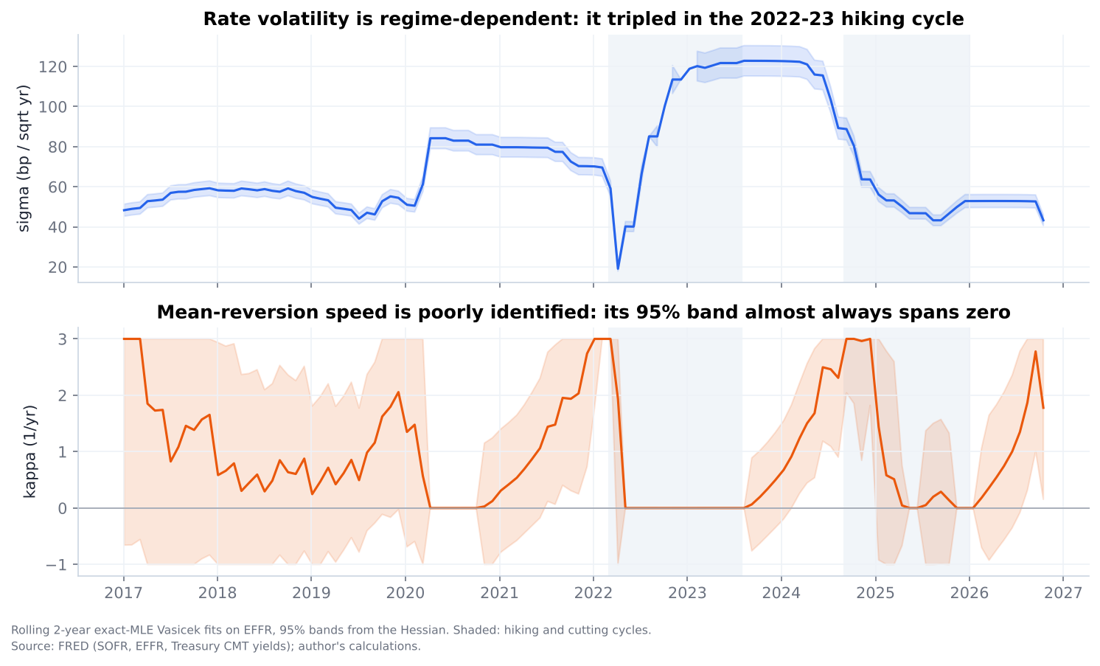

In [3]:
display(Image(filename="reports/figures/02_rolling_parameters.png"))

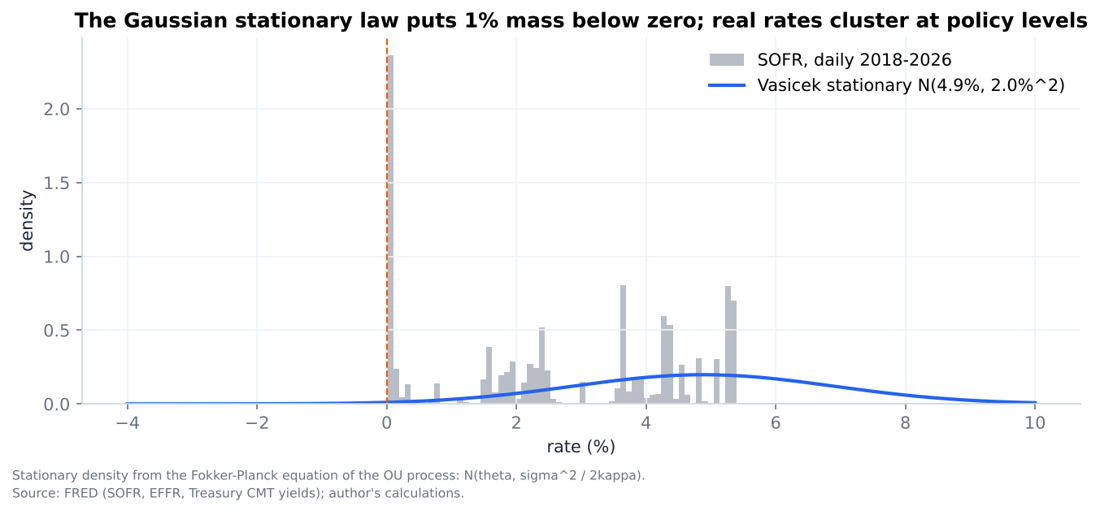

In [4]:
display(Image(filename="reports/figures/03_stationary_distribution.png"))

## 3. Monte Carlo accuracy

**Statistical error.** The Monte Carlo estimate of $P(0,T)=E[e^{-\int_0^T r\,ds}]$ has standard error $s/\sqrt N$ — 100× more paths for 10× more accuracy.

**Variance reduction.**
* *Antithetic variates*: pair every shock $z$ with $-z$. The pair average has lower variance because the two estimates are negatively correlated.
* *Control variate*: $Y=\int_0^T r\,ds$ is highly correlated with the payoff and its mean is known exactly, $E[Y]=\theta T + (r_0-\theta)(1-e^{-\kappa T})/\kappa$. Use $X + c\,(Y - E[Y])$ with $c = -\mathrm{Cov}(X,Y)/\mathrm{Var}(Y)$.

In [5]:
from ratesmc.montecarlo import convergence_table
r0 = float(sofr.iloc[-1])
exact, rows = convergence_table(r0, v["kappa"], v["theta"], v["sigma"], 2.0, [1000, 10000, 100000], 104, 7)
t = pd.DataFrame(rows); t["se_bp"] = t.se * 1e4; t["error_bp"] = t.error * 1e4
print(f"closed-form 2y bond price: {exact:.6f}")
print(t[["n", "method", "estimate", "se_bp", "error_bp"]].round(4).to_string(index=False))

closed-form 2y bond price: 0.923176
     n     method  estimate  se_bp  error_bp
  1000      plain    0.9234 4.2478    2.5669
  1000 antithetic    0.9232 0.0559   -0.0584
  1000    control    0.9232 0.0413   -0.0226
 10000      plain    0.9234 1.3184    1.9033
 10000 antithetic    0.9232 0.0191    0.0142
 10000    control    0.9232 0.0133    0.0014
100000      plain    0.9232 0.4185    0.2191
100000 antithetic    0.9232 0.0060    0.0042
100000    control    0.9232 0.0043    0.0052


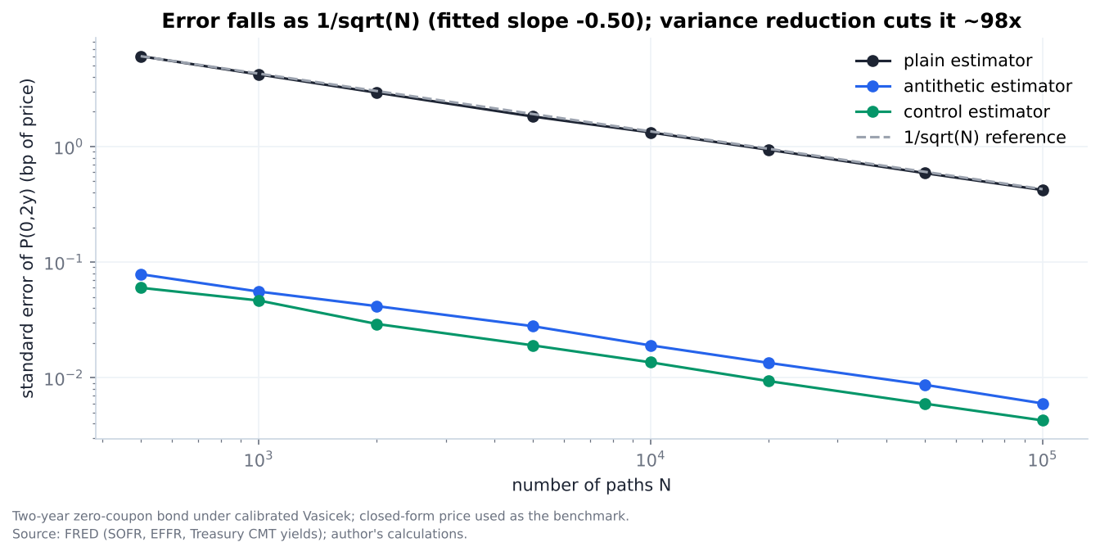

In [6]:
display(Image(filename="reports/figures/04_mc_convergence.png"))

**Discretisation error** is a different, systematic error: more paths do not remove it, only a smaller time step does. Euler–Maruyama has weak order 1. For CIR, Milstein adds the term $\tfrac14\sigma^2\Delta(z^2-1)$ and reaches strong order 1 vs ½ for Euler.

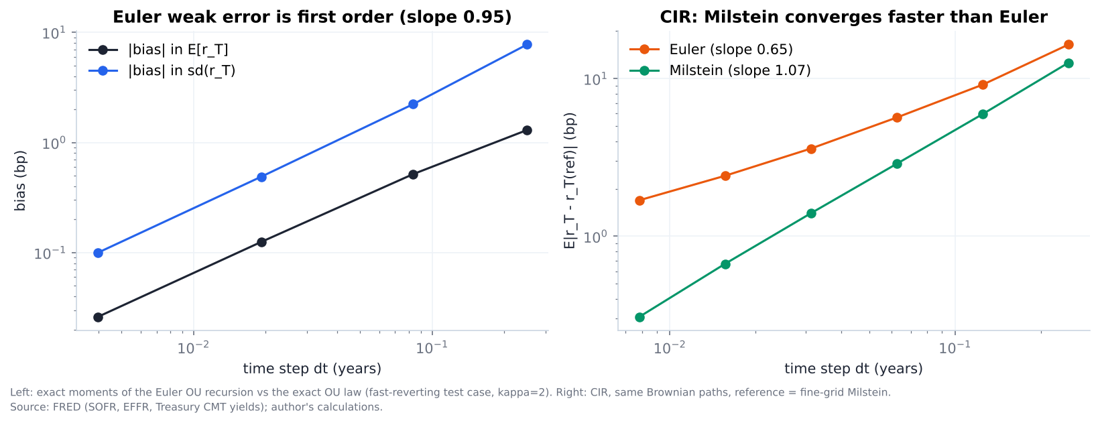

In [7]:
display(Image(filename="reports/figures/05_discretisation_error.png"))

## 4. Today's curve and the market's FOMC path

The Treasury curve (FRED, 1M–2Y) is shifted in parallel so its short end equals SOFR; its *shape* tells us how much hiking or cutting is priced. Hull–White's $\theta(t)$ is fitted to it, so the model reprices every point of the curve exactly.

For each FOMC meeting the expected change in the rate is split between the two neighbouring 25 bp outcomes (e.g. +10 bp expected → 40% chance of +25 bp, 60% of no change). This is the minimum-variance distribution consistent with the curve: it shows the market's central path, not its tail risk.

In [8]:
from ratesmc.models import HullWhite
from ratesmc.fomc import implied_moves
tg, zg = policy_curve(cfg, r0)
hw = HullWhite(tg, zg, cfg["pricing"]["hw_a"], v["sigma"])
moves, _ = implied_moves(hw, cfg["data"]["as_of"], cfg["fomc"]["meetings"], 2.0)
m = moves.head(6)[["meeting", "exp_change_bp", "p_upper", "exp_rate_after"]].copy()
m["p_hike_25bp_%"] = (m.pop("p_upper") * 100).round(0); m["exp_rate_after_%"] = (m.pop("exp_rate_after") * 100).round(3)
print(m.round(2).to_string(index=False))

   meeting  exp_change_bp  p_hike_25bp_%  exp_rate_after_%
2026-10-28           2.15            9.0              3.92
2026-12-09          18.94           76.0              4.11
2027-01-27           2.29            9.0              4.13
2027-03-17           4.81           19.0              4.18
2027-04-28           6.36           25.0              4.25
2027-06-16           5.31           21.0              4.30


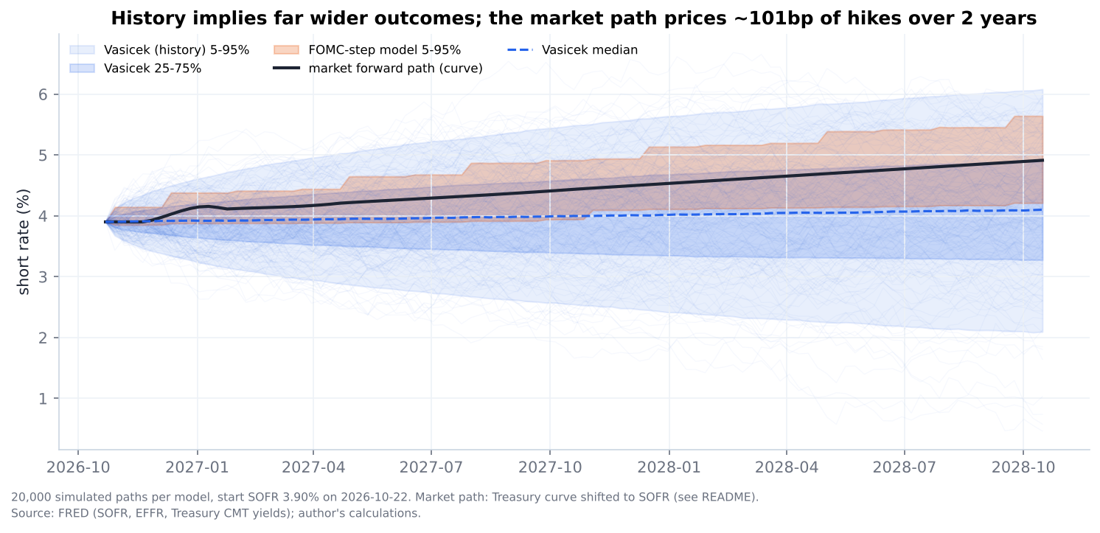

In [9]:
display(Image(filename="reports/figures/01_fan_chart.png"))

In [10]:
probs = pd.read_csv("reports/tables/scenario_probabilities.csv")
print(probs.round(3).to_string(index=False))

 horizon              model  p_hike_25plus  p_hike_50plus  p_cut_25plus  mean_change_bp  sd_bp
Dec-2026  Vasicek (history)          0.385          0.170         0.349           1.941 37.341
Dec-2026 FOMC step (market)          0.777          0.068         0.000          21.095 13.250
Jun-2027  Vasicek (history)          0.468          0.343         0.402           7.015 75.877
Jun-2027 FOMC step (market)          0.902          0.509         0.000          39.959 23.504
Dec-2027  Vasicek (history)          0.496          0.397         0.406          11.737 97.605
Dec-2027 FOMC step (market)          0.966          0.797         0.000          63.781 31.661


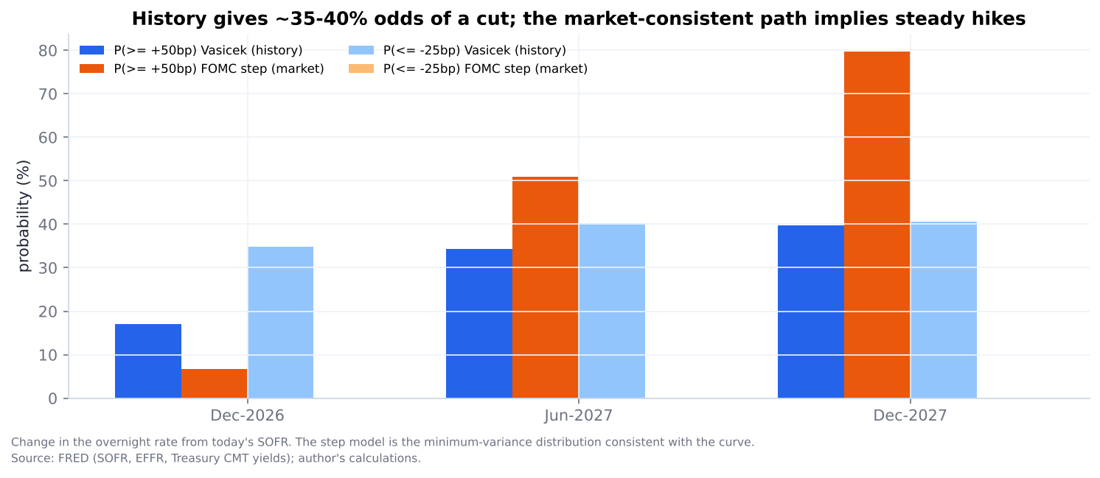

In [11]:
display(Image(filename="reports/figures/06_scenario_probabilities.png"))

**Reading it.** History (Vasicek) says almost anything can happen: a ~35–40% chance of at least a 25 bp cut. The curve says the market expects steady hikes (~100 bp over two years). The gap is the point of the comparison: a model calibrated to the past ignores the market's information, while the market-consistent step path ignores how wrong the market has been before (see the Fed-pricing project: 12-month errors average ~69 bp).

## 5. Pricing: a caplet and the futures convexity adjustment

**Caplet** on the 3-month rate in one year, strike 4.50%: Hull–White has a closed form (a put on a zero-coupon bond). Monte Carlo must agree within its confidence interval.

**Convexity adjustment.** Futures are margined daily: when rates rise, a short futures position gains cash that can be reinvested at higher rates. So futures rates sit above forward rates, by $\frac{B(T_1,T_2)}{\tau}\left[B(T_1,T_2)(1-e^{-2aT_1}) + 2aB(0,T_1)^2\right]\frac{\sigma^2}{4a}$ in Hull–White.

In [12]:
import json
res = json.load(open("reports/results.json"))
cp = res["caplet"]
print(f"caplet closed form: {cp['closed_form']*1e4:.3f} bp of notional")
for e in cp["mc"]:
    print(f"  Monte Carlo N={e['n']:>7,}: {e['price']*1e4:.3f} bp  (95% CI ±{1.96*e['se']*1e4:.3f})")
print("convexity adjustment (bp):", {k: round(v_, 2) for k, v_ in res["convexity"].items() if k.startswith("at_")})

caplet closed form: 8.608 bp of notional
  Monte Carlo N= 10,000: 8.634 bp  (95% CI ±0.241)
  Monte Carlo N=100,000: 8.675 bp  (95% CI ±0.076)
convexity adjustment (bp): {'at_1y': 0.48, 'at_2y': 1.49, 'at_5y': 5.78}


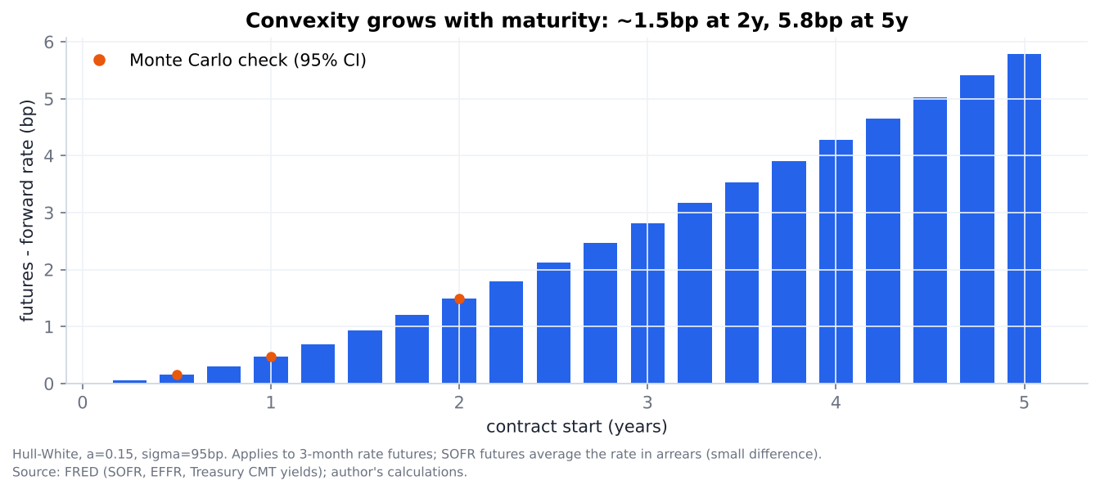

In [13]:
display(Image(filename="reports/figures/07_convexity_adjustment.png"))

## 6. Risk: one-month VaR and Expected Shortfall

Long one SR3 contract on the quarter starting in ~6 months ($25 per bp). Under Vasicek the futures rate moves by $L \times \Delta r$ with $L$ the average of $e^{-\kappa(s-t)}$ over the reference quarter. **VaR** is a quantile of the loss; **Expected Shortfall** is the average loss beyond it, so it sees the tail.

In [14]:
print(pd.read_csv("reports/tables/var_es.csv").round(0).to_string(index=False))

                method  VaR95   ES95  VaR99   ES99
 Monte Carlo (Vasicek) 1077.0 1351.0 1525.0 1746.0
Historical (2018-2026) 1177.0 1654.0 1812.0 1850.0


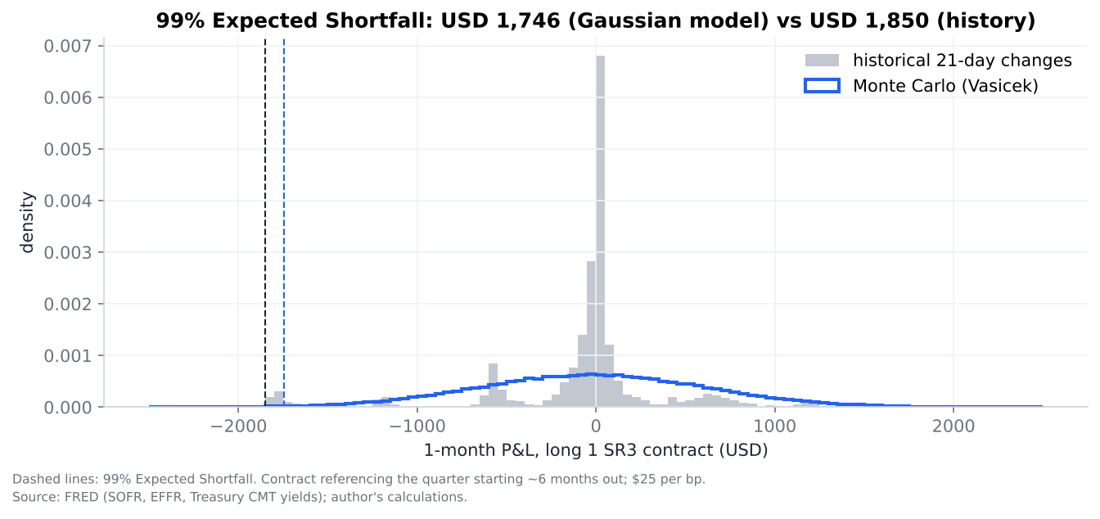

In [15]:
display(Image(filename="reports/figures/08_var_es.png"))

**Reading it.** The Gaussian model gets the 95% VaR roughly right but understates the extreme tail: history (2020 emergency cuts, 2022 75 bp hikes) is peaked with fat tails. A jump component at FOMC dates, sized from the meeting probabilities, is the natural extension.

## 7. Limitations
* History-based κ is weakly identified; the long-run level θ is close to meaningless as a forecast.
* One-factor models move all maturities together (no curve twists).
* The market path uses the Treasury curve shifted to SOFR, not SR3 futures; the two-outcome FOMC split understates tails.
* Hull–White parameters are history-based; a desk would calibrate them to cap/swaption volatilities.
* SOFR futures average the rate in arrears; the convexity formula is for a forward-looking 3-month rate (small difference).